In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

df = pd.read_csv('./datayobit1h.csv')

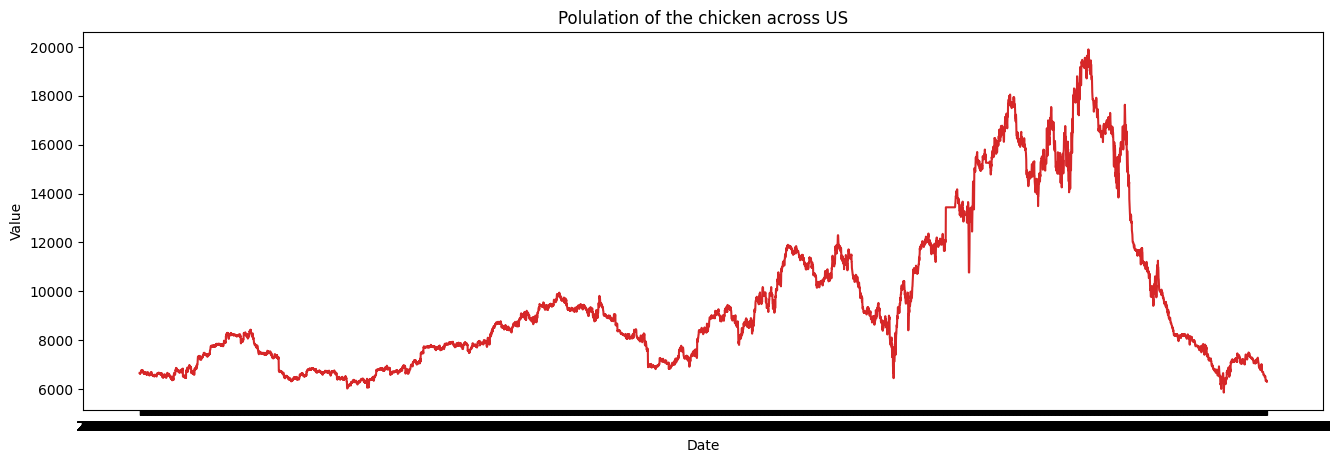

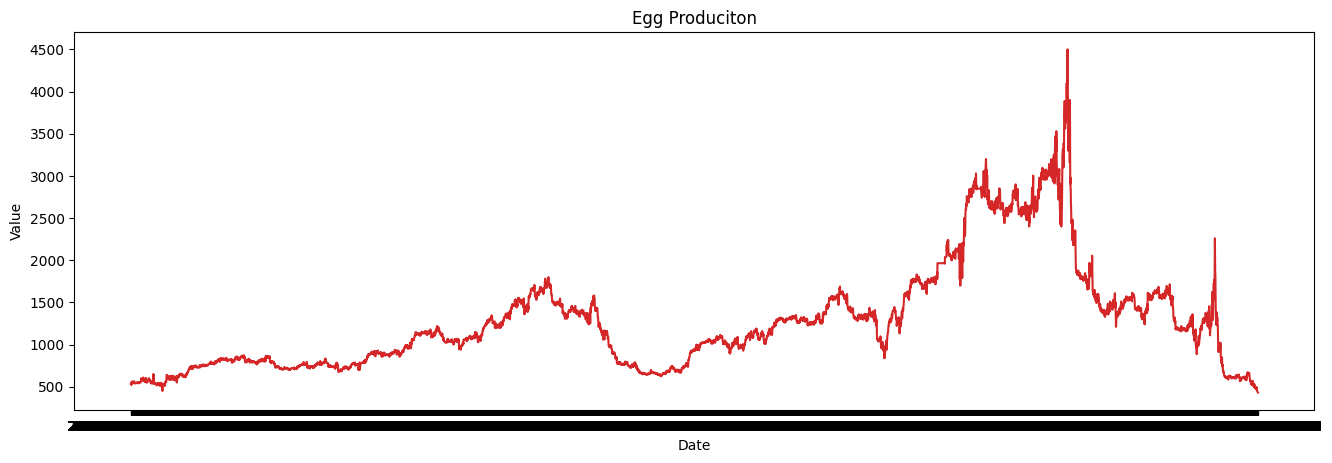

In [8]:
# Draw Plot
def plot_df(df, x, y, title="", xlabel='Date', ylabel='Value', dpi=100):
    plt.figure(figsize=(16,5), dpi=dpi)
    plt.plot(x, y, color='tab:red')
    plt.gca().set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.show()
plot_df(df, x=df.Date, y=df.btc, title='Polulation of the chicken across US')   
plot_df(df, x=df.Date, y=df.bch, title='Egg Produciton')

In [7]:
df

,Date,btc,bch,btg,dash,doge,eso,etc,eth,liz,ltc,trx,waves,xem,xvg,zec
0,2018-08-22 11-PM,6655.00,535.02,14.65,140.50,0.002432,6.010,12.80,278.74,0.3745,57.71,0.02032,2.15,0.1178,0.012950,130.80
1,2018-08-22 10-PM,6655.00,535.02,14.65,140.50,0.002432,6.010,12.80,278.74,0.3745,57.71,0.02032,2.14,0.1178,0.012950,130.80
2,2018-08-22 09-PM,6613.40,535.02,14.65,140.50,0.002475,6.010,12.74,274.73,0.3745,58.18,0.02072,2.14,0.1178,0.012950,131.00
3,2018-08-22 08-PM,6630.50,525.00,14.52,140.50,0.002456,6.010,12.74,279.87,0.3500,56.95,0.02082,2.14,0.1133,0.012980,131.99
4,2018-08-22 07-PM,6655.00,521.23,14.97,144.00,0.002442,6.090,12.80,280.00,0.2320,57.18,0.02140,2.19,0.1132,0.012980,131.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7050,2017-11-01 04-AM,6323.35,441.39,233.39,275.17,0.001108,0.750,10.30,300.80,0.0000,54.72,0.00000,3.09,0.1842,0.007081,227.01
7051,2017-11-01 03-AM,6317.02,438.20,230.00,275.20,0.001117,0.750,10.31,301.00,0.0000,54.83,0.00000,3.09,0.1842,0.006216,228.90
7052,2017-11-01 02-AM,6348.00,432.16,232.20,275.48,0.001117,0.750,10.32,301.94,0.0000,54.83,0.00000,3.10,0.1842,0.007187,228.91
7053,2017-11-01 01-AM,6343.00,432.16,251.44,275.30,0.001131,0.681,10.32,301.49,0.0000,55.66,0.00000,3.15,0.1842,0.007187,228.91


In [27]:
# Check to see if the distribution is stationary using ADF test
from statsmodels.tsa.stattools import adfuller

def check_df(df, p_val):
    
    for col in df.columns[1:]:
        res = adfuller(df[col])
        
        if res[1] > p_val:
            print(f'{col} series is not stationary')
        else:
            print(f'{col} series is stationary')
            
check_df(df, 0.05)

btc series is not stationary
bch series is not stationary
btg series is not stationary
dash series is not stationary
doge series is not stationary
eso series is not stationary
etc series is not stationary
eth series is not stationary
liz series is stationary
ltc series is not stationary
trx series is not stationary
waves series is not stationary
xem series is not stationary
xvg series is not stationary
zec series is not stationary


In [14]:
df_transformed = df.iloc[:,1:].diff().dropna()

In [28]:
# Given that in the first oder differencing all the series are stationary there is no need for a secondary diffrenciation
check_df(df_transformed, 0.05)

bch series is stationary
btg series is stationary
dash series is stationary
doge series is stationary
eso series is stationary
etc series is stationary
eth series is stationary
liz series is stationary
ltc series is stationary
trx series is stationary
waves series is stationary
xem series is stationary
xvg series is stationary
zec series is stationary


In [33]:
from statsmodels.tsa.stattools import grangercausalitytests

grangercausalitytests(df_transformed[['btc', 'bch']], maxlag=5)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=22.8434 , p=0.0000  , df_denom=7050, df_num=1
ssr based chi2 test:   chi2=22.8531 , p=0.0000  , df=1
likelihood ratio test: chi2=22.8161 , p=0.0000  , df=1
parameter F test:         F=22.8434 , p=0.0000  , df_denom=7050, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=14.4732 , p=0.0000  , df_denom=7047, df_num=2
ssr based chi2 test:   chi2=28.9670 , p=0.0000  , df=2
likelihood ratio test: chi2=28.9076 , p=0.0000  , df=2
parameter F test:         F=14.4732 , p=0.0000  , df_denom=7047, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=11.0503 , p=0.0000  , df_denom=7044, df_num=3
ssr based chi2 test:   chi2=33.1840 , p=0.0000  , df=3
likelihood ratio test: chi2=33.1061 , p=0.0000  , df=3
parameter F test:         F=11.0503 , p=0.0000  , df_denom=7044, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=9.1249  , p=0.

{1: ({'ssr_ftest': (22.843372974073834, 1.7931474532135022e-06, 7050.0, 1),
   'ssr_chi2test': (22.853093558318122, 1.7486764589835237e-06, 1),
   'lrtest': (22.81614910477947, 1.7826150756481494e-06, 1),
   'params_ftest': (22.843372974074555, 1.7931474532126962e-06, 7050.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (14.473220846030252, 5.336227512918774e-07, 7047.0, 2),
   'ssr_chi2test': (28.96697982296164, 5.127436052849682e-07, 2),
   'lrtest': (28.90764947637217, 5.281820937410731e-07, 2),
   'params_ftest': (14.473220846030097, 5.336227512922556e-07, 7047.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (11.050343626654627, 3.1045374421188683e-07, 7044.0, 3),
   'ssr_chi2test': (33.18397483455782, 2.9453513757746305e-07, 3),
   'lrtest': (33.106132445303956, 3.058853599491493e-07, 3),
   'params_ftest': (11.05034362665438, 3.1045374421196735e-07, 7044.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 